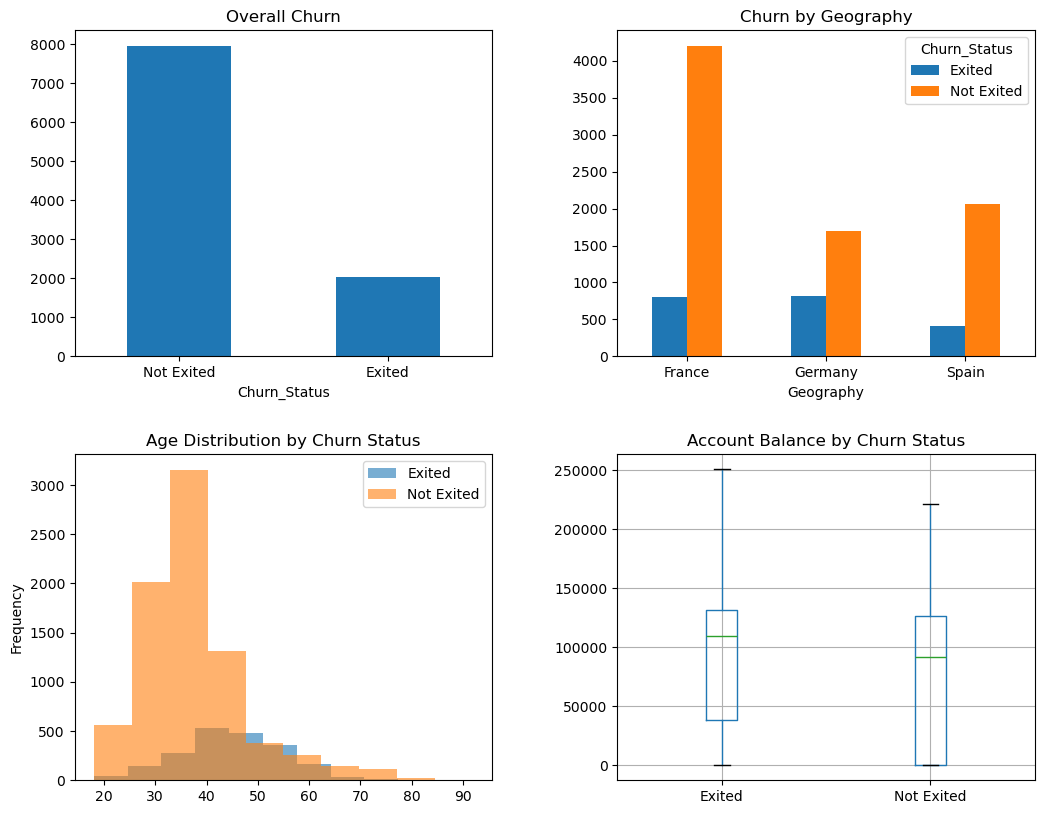

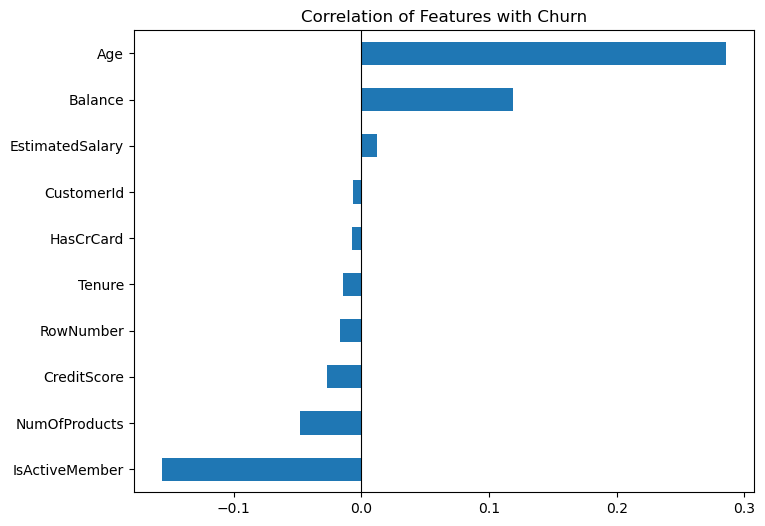

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# ---- 1. Setup ----
df = pd.read_csv('Churn_Modelling.csv')
df['Churn_Status'] = df['Exited'].map({0: 'Not Exited', 1: 'Exited'})
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# ---- 2. Plot 1: Overall churn (top-left) ----
df['Churn_Status'].value_counts().plot(kind='bar', ax=axes[0, 0], rot=0)
axes[0, 0].set_title('Overall Churn')

# ---- 3. Plot 2: Churn by geography (top-right) ----
pd.crosstab(df['Geography'], df['Churn_Status']).plot(kind='bar', ax=axes[0, 1], rot=0)
axes[0, 1].set_title('Churn by Geography')

# ---- 4. Plot 3: Age distribution (bottom-left) ----
df.groupby('Churn_Status')['Age'].plot(kind='hist', alpha=0.6, legend=True, ax=axes[1, 0])
axes[1, 0].set_title('Age Distribution by Churn Status')

# ---- 5. Plot 4: Account balance (bottom-right) ----
df.boxplot(column='Balance', by='Churn_Status', ax=axes[1, 1])
plt.suptitle('')
axes[1, 1].set_xlabel('')
axes[1, 1].set_title('Account Balance by Churn Status')

# ---- 6. Layout and display ----
plt.subplots_adjust(hspace=0.3, wspace=0.3)
plt.show()

# ---- 7. Plot 5: Feature correlation (separate figure) ----
plt.figure(figsize=(8, 6))
df.corr(numeric_only=True)['Exited'].drop('Exited').sort_values().plot(kind='barh')
plt.axvline(x=0, color='black', linewidth=0.8)
plt.title('Correlation of Features with Churn')
plt.show()


## Python Charts and Their Use Cases
The script produces a 2×2 figure (Plots 1–4) and one separate chart (Plot 5).

### Plot 1: Overall Churn (Bar chart)
- **Question it answers:** What share of customers is leaving?
- **Use case:** Gives the baseline retention rate and shows the class imbalance in the data, before digging into reasons. Important when building prediction models, since a model can look accurate just by always guessing "stays".

### Plot 2: Churn by Geography (Grouped bar chart)
- **Question it answers:** Where is churn worst?
- **Use case:** Geographic segment analysis. If one country's Exited bar is disproportionately high versus its own Not Exited bar, the problem is local (competitors, service, pricing) and not company-wide.

### Plot 3: Age Distribution by Churn Status (Overlapping histograms)
- **Question it answers:** Which age groups are leaving?
- **Use case:** Demographic profiling. If leavers are older, use relationship-led retention offers; if younger, focus on engagement and onboarding.

### Plot 4: Account Balance by Churn Status (Box plot)
- **Question it answers:** Are we losing high-value clients?
- **Use case:** Shows the financial impact of churn. A higher box for "Exited" means leavers hold more money, so they are the top priority for personal outreach by relationship managers.

### Plot 5: Correlation of Features with Churn (Horizontal bar chart)
- **Question it answers:** Which factors drive churn?
- **Use case:** Driver analysis for executives. Bars pointing right increase churn, bars pointing left decrease it[cite: 2]. Longer bar = stronger relationship. Ignore ID-style columns (row number, customer ID) and remember that correlation is not causation.

---

## Summary

| Chart | Type | Business use |
| :--- | :--- | :--- |
| **Overall Churn** | Bar | Sets baseline retention target |
| **By Geography** | Grouped bars | Targets regional fixes and campaigns |
| **Age** | Overlapping histograms | Shapes marketing and retention offers|
| **Balance** | Box plot | Prioritizes personal outreach|
| **Correlation** | Horizontal bars | Guides where to investigate first |

---

## Key Takeaways
- Establish the overall churn rate first, then segment it by geography, age, and balance.
- Focus retention effort on the segments with the highest churn and highest balances.
- Use the correlation chart to decide which variables to study in more depth.